# Практическая работа. Анализ временных рядов  
## Часть 2. Построение и сравнение моделей прогнозирования

Во второй части используется тот же набор данных.

---

## Цель работы

Научиться корректно строить и сравнивать модели прогнозирования временных рядов.

В работе рассматриваются:

1. **Базовые модели**
   - Naive;
   - Seasonal Naive.

2. **Классические статистические модели**
   - AR;
   - MA;
   - ARMA;
   - ARIMA;
   - SARIMA.

3. **Экспоненциальное сглаживание**
   - Holt–Winters.

4. **Машинное обучение**
   - XGBoost с лаговыми и скользящими признаками.

---

Сложная модель полезна только в том случае, если она дает качество лучше простого baseline.

> **Важно:** данные временного ряда нельзя случайным образом перемешивать при разбиении на обучающую и тестовую выборки.

# 0. Подготовка окружения

In [28]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit

import pmdarima as pm
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox

try:
    from xgboost import XGBRegressor
    XGBOOST_AVAILABLE = True
except ImportError:
    XGBOOST_AVAILABLE = False
    print(
        "XGBoost не установлен. "
        "Установите его командой: pip install xgboost"
    )

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# 1. Вспомогательные функции

In [29]:
def rmse(y_true, y_pred):
    """Root Mean Squared Error."""
    return np.sqrt(mean_squared_error(y_true, y_pred))


def mase(y_true, y_pred, y_train, seasonality=1):
    """
    Mean Absolute Scaled Error.

    Масштабирование выполняется относительно наивного прогноза,
    рассчитанного на обучающей выборке.

    MASE < 1  -> модель в среднем лучше наивного прогноза.
    MASE > 1  -> модель хуже наивного прогноза.
    """
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    y_train = np.asarray(y_train)

    if len(y_train) <= seasonality:
        return np.nan

    scale = np.mean(
        np.abs(y_train[seasonality:] - y_train[:-seasonality])
    )

    if scale == 0:
        return np.nan

    return np.mean(np.abs(y_true - y_pred)) / scale


def evaluate_forecast(
    y_true,
    y_pred,
    y_train,
    model_name,
    mase_seasonality=1
):
    """Возвращает основные метрики прогноза."""
    return {
        "Модель": model_name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": rmse(y_true, y_pred),
        "MASE": mase(
            y_true,
            y_pred,
            y_train,
            seasonality=mase_seasonality
        ),
        "R2": r2_score(y_true, y_pred)
    }


def plot_forecast(
    train,
    test,
    prediction,
    title="Прогноз",
    last_train_points=180,
    figsize=(14, 6)
):
    """
    Строит обучающую часть, тест и прогноз.
    Для читаемости показывает последние last_train_points train-наблюдений.
    """
    train_part = train.iloc[-last_train_points:]

    plt.figure(figsize=figsize)
    plt.plot(
        train_part.index,
        train_part.values,
        label="Train",
        alpha=0.75
    )
    plt.plot(
        test.index,
        test.values,
        label="Test / факт",
        linewidth=2
    )
    plt.plot(
        test.index,
        np.asarray(prediction),
        label="Прогноз",
        linewidth=2
    )

    plt.title(title)
    plt.xlabel("Время")
    plt.ylabel(test.name if test.name else "Значение")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.show()


def naive_forecast(train, test):
    """
    Naive:
    все значения тестового периода равны последнему наблюдению train.
    """
    return pd.Series(
        np.repeat(train.iloc[-1], len(test)),
        index=test.index,
        name="naive"
    )


def seasonal_naive_forecast(train, test, seasonality=7):
    """
    Seasonal Naive:
    повторяется последнее известное сезонное окно.
    """
    if len(train) < seasonality:
        raise ValueError(
            "Обучающая выборка короче сезонного периода."
        )

    last_season = train.iloc[-seasonality:].values

    pred = np.resize(
        last_season,
        len(test)
    )

    return pd.Series(
        pred,
        index=test.index,
        name=f"seasonal_naive_{seasonality}"
    )


def create_time_features(index):
    """Календарные признаки."""
    features = pd.DataFrame(index=index)

    features["day_of_week"] = index.dayofweek
    features["month"] = index.month
    features["day_of_year"] = index.dayofyear

    # Циклическое кодирование:
    features["dow_sin"] = np.sin(
        2 * np.pi * features["day_of_week"] / 7
    )
    features["dow_cos"] = np.cos(
        2 * np.pi * features["day_of_week"] / 7
    )

    features["month_sin"] = np.sin(
        2 * np.pi * (features["month"] - 1) / 12
    )
    features["month_cos"] = np.cos(
        2 * np.pi * (features["month"] - 1) / 12
    )

    features["doy_sin"] = np.sin(
        2 * np.pi * (features["day_of_year"] - 1) / 365.25
    )
    features["doy_cos"] = np.cos(
        2 * np.pi * (features["day_of_year"] - 1) / 365.25
    )

    return features


def make_ml_features(
    df,
    target,
    lags=(1, 2, 3, 7, 14, 30),
    rolling_windows=(7, 14, 30),
    extra_features=None
):
    """
    Создает признаки для модели машинного обучения.

    ВАЖНО:
    rolling_mean и rolling_std обязательно рассчитываются
    после shift(1), чтобы текущая цель y_t не попадала в признаки.
    """
    result = pd.DataFrame(index=df.index)

    # Календарные признаки
    result = result.join(create_time_features(df.index))

    # Лаги целевой переменной
    for lag in lags:
        result[f"{target}_lag_{lag}"] = df[target].shift(lag)

    # Скользящие статистики только по прошлым значениям
    shifted_target = df[target].shift(1)

    for window in rolling_windows:
        result[f"{target}_rolling_mean_{window}"] = (
            shifted_target.rolling(window).mean()
        )
        result[f"{target}_rolling_std_{window}"] = (
            shifted_target.rolling(window).std()
        )
        result[f"{target}_rolling_min_{window}"] = (
            shifted_target.rolling(window).min()
        )
        result[f"{target}_rolling_max_{window}"] = (
            shifted_target.rolling(window).max()
        )

    # Дополнительные признаки.
    # Используем только предыдущие значения, чтобы не подсматривать в будущее.
    if extra_features is not None:
        for feature in extra_features:
            if feature in df.columns:
                result[f"{feature}_lag_1"] = df[feature].shift(1)
                result[f"{feature}_lag_7"] = df[feature].shift(7)

    # Цель
    result[target] = df[target]

    return result.dropna()


def plot_residuals(y_true, y_pred, model_name, lags=30):
    """График остатков и их ACF."""
    residuals = pd.Series(
        np.asarray(y_true) - np.asarray(y_pred),
        index=y_true.index,
        name="residual"
    )

    fig, axes = plt.subplots(2, 1, figsize=(14, 8))

    axes[0].plot(residuals.index, residuals.values)
    axes[0].axhline(0, linestyle="--")
    axes[0].set_title(f"Остатки: {model_name}")
    axes[0].grid(alpha=0.25)

    safe_lags = min(lags, max(1, len(residuals) // 2 - 1))
    plot_acf(residuals.dropna(), lags=safe_lags, ax=axes[1])
    axes[1].set_title(f"ACF остатков: {model_name}")

    plt.tight_layout()
    plt.show()

    return residuals


def ljung_box_test(residuals, lags=(7, 14, 21)):
    """
    Тест Льюнга-Бокса.

    H0: остатки не содержат значимой автокорреляции.
    p < 0.05 -> есть основания считать, что в остатках
    еще осталась временная структура.
    """
    clean = pd.Series(residuals).dropna()

    valid_lags = [
        lag for lag in lags
        if lag < len(clean)
    ]

    return acorr_ljungbox(
        clean,
        lags=valid_lags,
        return_df=True
    )

In [30]:
def invert_first_difference(last_observation, diff_forecast, index):
    """
    Восстанавливает прогноз исходного ряда из прогноза первых разностей.

    Если:
        Δy_t = y_t - y_(t-1),

    то:
        y_(t+h) = y_t + Σ Δy
    """
    diff_forecast = np.asarray(diff_forecast, dtype=float)

    restored = last_observation + np.cumsum(diff_forecast)

    return pd.Series(
        restored,
        index=index
    )

# 2. Загрузка данных

In [70]:
DATA_PATH = "data.csv"
DATE_COLUMN = "DATE"
TARGET = "UK"

df = pd.read_csv(
    DATA_PATH
)
t = pd.date_range('1/1/1986', periods = 262968, freq = 'h')
df['DATE'] = t

dataset = (
    df
    .set_index(DATE_COLUMN)
    .sort_index()
)

series = dataset[TARGET].astype(float)

print("Период:", dataset.index.min(), "—", dataset.index.max())
print("Количество наблюдений:", len(dataset))

dataset.head()


series = dataset.loc['1986-01-01 00:00:00':'1991-12-31 23:00:00', TARGET].astype(float)

display(dataset.head())
print("Период:", dataset.index.min(), "—", dataset.index.max())
print("Количество наблюдений:", len(dataset))

Период: 1986-01-01 00:00:00 — 2015-12-31 23:00:00
Количество наблюдений: 262968


,AT,BE,BG,CH,CY,CZ,DE,DK,EE,ES,FI,FR,EL,HR,HU,IE,IT,LT,LU,LV,NL,NO,PL,PT,RO,SI,SK,SE,UK
DATE,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1986-01-01 00:00:00,0.0000,0.0000,0.0000,0.0000,0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
1986-01-01 01:00:00,0.0000,0.0000,0.0000,0.0000,0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
1986-01-01 02:00:00,0.0000,0.0000,0.0000,0.0000,0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
1986-01-01 03:00:00,0.0000,0.0000,0.0000,0.0000,0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
1986-01-01 04:00:00,0.0000,0.0000,0.0000,0.0000,0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


Период: 1986-01-01 00:00:00 — 2015-12-31 23:00:00
Количество наблюдений: 262968


# 3. Формирование обучающей и тестовой выборок

Для временных рядов нельзя использовать случайное перемешивание.

Правильная схема:

```text
прошлое                         будущее
████████████████████████████ | ████████
            TRAIN             |   TEST
```

В качестве основного варианта используем последние **20% наблюдений** как тест.

При необходимости преподаватель может задать конкретную дату разделения.

In [71]:
TEST_SIZE = 0.20

split_idx = int(len(series) * (1 - TEST_SIZE))

train = series.iloc[:split_idx]
test = series.iloc[split_idx:]

print("TRAIN:")
print("  период:", train.index.min(), "—", train.index.max())
print("  наблюдений:", len(train))

print("\nTEST:")
print("  период:", test.index.min(), "—", test.index.max())
print("  наблюдений:", len(test))

TRAIN:
  период: 1986-01-01 00:00:00 — 1990-10-19 18:00:00
  наблюдений: 42067

TEST:
  период: 1990-10-19 19:00:00 — 1991-12-31 23:00:00
  наблюдений: 10517


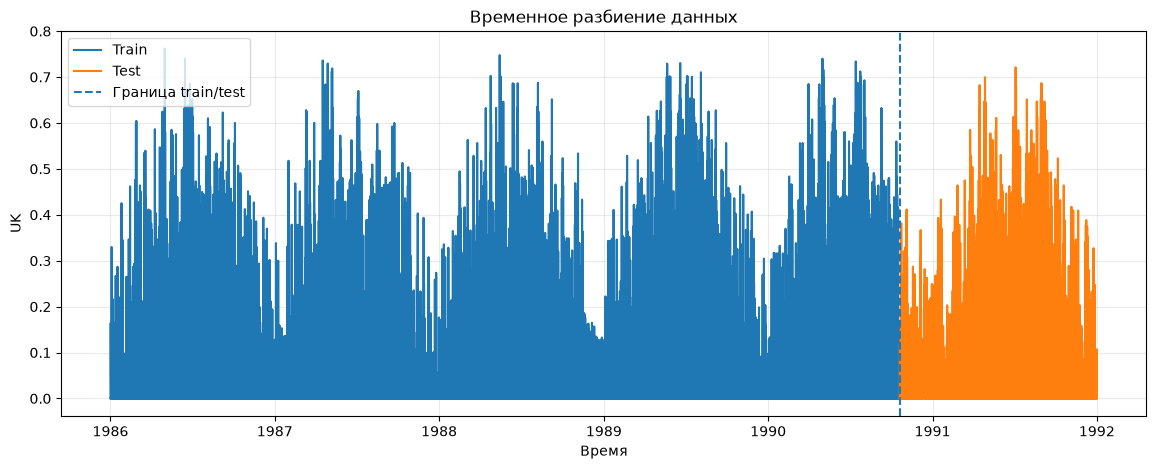

In [72]:
plt.figure(figsize=(14, 5))
plt.plot(train.index, train.values, label="Train")
plt.plot(test.index, test.values, label="Test")
plt.axvline(test.index[0], linestyle="--", label="Граница train/test")
plt.title("Временное разбиение данных")
plt.xlabel("Время")
plt.ylabel(TARGET)
plt.legend()
plt.grid(alpha=0.25)
plt.show()

### Задание 1

1. Почему нельзя использовать `train_test_split(..., shuffle=True)`?
2. Какой период попал в обучающую выборку?
3. Какой период используется для итогового тестирования?
4. Почему тестовая выборка должна находиться **после** обучающей во времени?

### Вывод

Случайное перемешивание нарушает хронологический порядок наблюдений и приводит к утечке данных из будущего в прошлое (data leakage). Модель на этапе обучения увидит будущие значения ряда, что недопустимо в реальных задачах прогнозирования и даст искусственно завышенные метрики качества.Какой период попал в обучающую выборку?

Период с 1986-01-01 00:00:00 по 1990-10-19 18:00:00 (42 067 почасовых наблюдений).
Период с 1990-10-19 19:00:00 по 1991-12-31 23:00:00 (10 517 почасовых наблюдений — последние 20% выборки).

Это имитирует реальный процесс эксплуатации модели: мы обучаем алгоритм исключительно на доступной исторической информации, чтобы предсказывать неизвестные будущие периоды.

Принцип временного разбиения (out-of-time validation) заключается в строгом разделении ряда по временной оси на прошлое (train) и будущее (test) без перемешивания. Это сохраняет автокорреляционную структуру, тренд и сезонность ряда, а также гарантирует честную оценку обобщающей способности модели.  

# 4. Базовые модели

Перед сложными методами необходимо построить baseline.

Это позволяет ответить на главный вопрос:

> действительно ли сложная модель прогнозирует лучше очень простого правила?

## 4.1 Naive Forecast

Наивная модель предполагает:

$
\hat{y}_{t+h}=y_t
$

То есть будущие значения равны последнему известному значению.

,Модель,MAE,RMSE,MASE,R2
0,Naive,0.0819,0.1554,2.8891,-0.3846


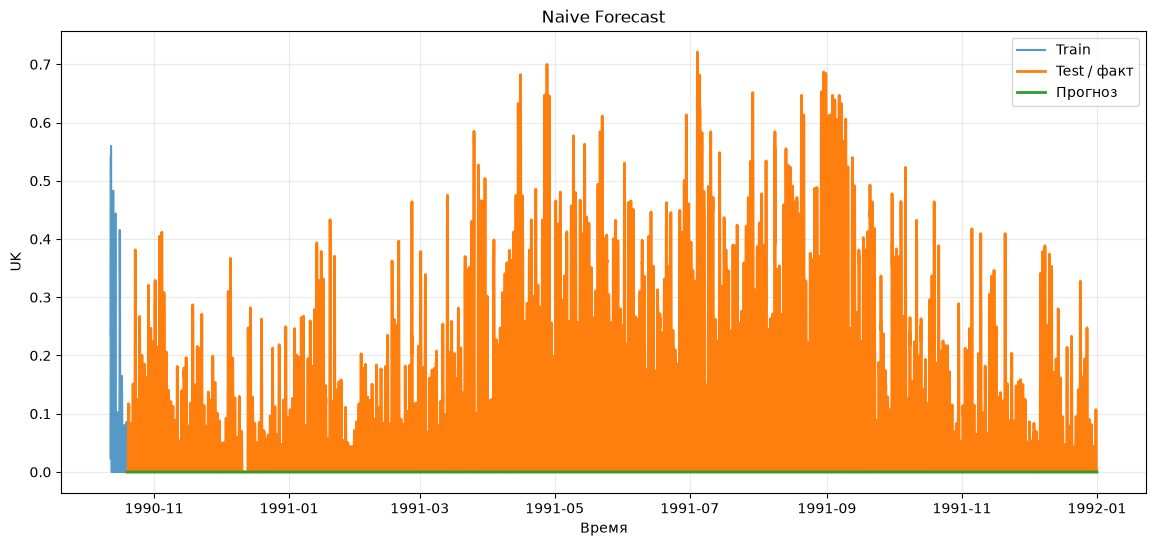

In [73]:
pred_naive = naive_forecast(train, test)

metrics_naive = evaluate_forecast(
    y_true=test,
    y_pred=pred_naive,
    y_train=train,
    model_name="Naive"
)

display(pd.DataFrame([metrics_naive]))

plot_forecast(
    train,
    test,
    pred_naive,
    title="Naive Forecast"
)

## 4.2 Seasonal Naive

Если наблюдается недельная сезонность:

$
\hat{y}_t = y_{t-7}
$

То есть прогноз повторяет значения предыдущего сезонного периода.

,Модель,MAE,RMSE,MASE,R2
0,Naive,0.0819,0.1554,2.8891,-0.3846
1,Seasonal Naive (168),0.0609,0.1171,2.1470,0.2139


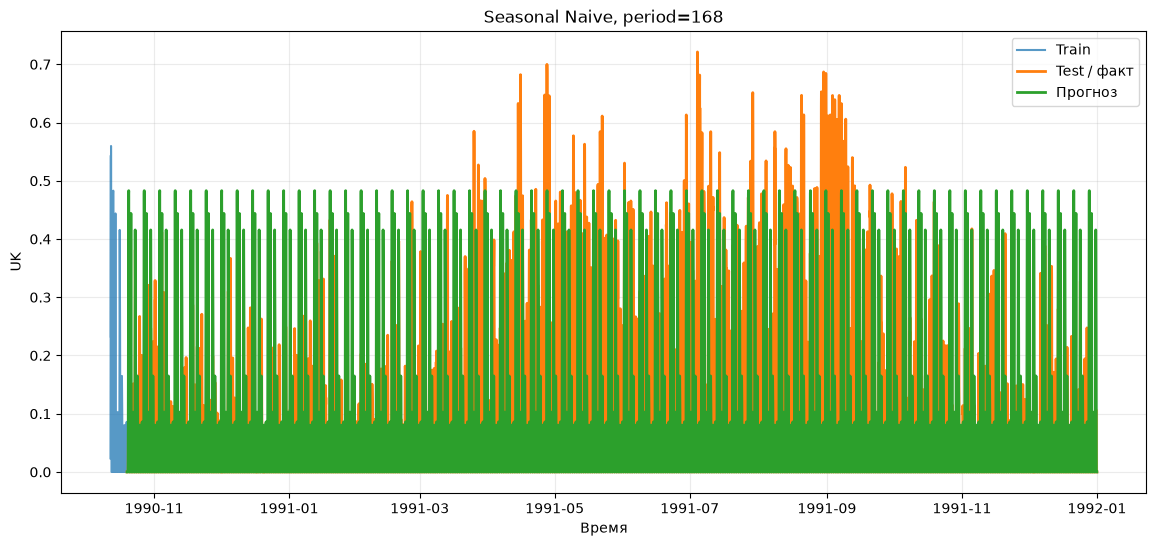

In [79]:
year = 87604
season = int(year/4)
month = int(season/3)
week = 168

SEASONAL_PERIOD = week

pred_seasonal_naive = seasonal_naive_forecast(
    train,
    test,
    seasonality=SEASONAL_PERIOD
)

metrics_seasonal_naive = evaluate_forecast(
    y_true=test,
    y_pred=pred_seasonal_naive,
    y_train=train,
    model_name=f"Seasonal Naive ({SEASONAL_PERIOD})"
)

display(pd.DataFrame([
    metrics_naive,
    metrics_seasonal_naive
]))

plot_forecast(
    train,
    test,
    pred_seasonal_naive,
    title=f"Seasonal Naive, period={SEASONAL_PERIOD}"
)

### Задание 2

Сравните Naive и Seasonal Naive.

1. Какая модель имеет меньший MAE?
2. Какая имеет меньший RMSE?
3. Что показывает MASE?
4. Улучшает ли учет недельной сезонности прогноз?

### Вывод

MAE: у Seasonal Naive (168) он меньше, 0.0609 против 0.0819 у Naive.

RMSE: тоже меньше у Seasonal Naive, 0.1171 против 0.1554.

MASE: это ошибка модели, делённая на среднюю ошибку одношагового наивного прогноза на train. У Naive он равен 2.889, у Seasonal Naive 2.147. Оба значения больше 1. Причина в том, что мы прогнозируем на 10 517 часов вперёд, а знаменатель считается на 1 час вперёд. Поэтому MASE здесь завышен по построению и сравнивать его с единицей нужно осторожно.

Учёт сезонности. Он явно помогает: R² вырос с −0.385 до +0.214, ошибки снизились. Недельный цикл (168 ч) в ряде действительно есть.
Лучший baseline — Seasonal Naive (168). Любая сложная модель должна быть лучше него.

# 5. Классические модели: AR, MA, ARMA и ARIMA

Модели этого семейства удобно рассматривать последовательно:

$
AR \rightarrow MA \rightarrow ARMA \rightarrow ARIMA
$

Это позволяет понять, какие компоненты постепенно добавляются в модель.

---

## Важное замечание о стационарности

Классические модели **AR, MA и ARMA предполагают стационарность ряда**.

Если в первой части практической работы было установлено, что исходный ряд нестационарен, его необходимо преобразовать.

В этом примере для AR, MA и ARMA используется **первая разность**:

$
\Delta y_t = y_t - y_{t-1}
$

После получения прогноза разностей выполняется обратное преобразование, чтобы получить прогноз исходного ряда.

Для ARIMA дифференцирование уже входит в саму модель через параметр `d`.

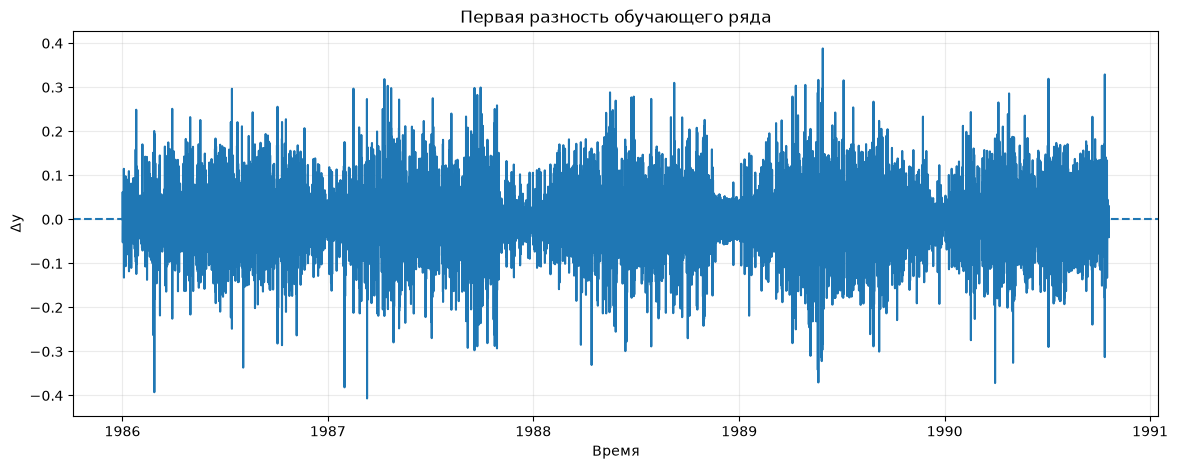

Количество наблюдений: 42066


In [36]:
# Первая разность обучающего ряда
train_diff = train.diff().dropna()

plt.figure(figsize=(14, 5))
plt.plot(train_diff.index, train_diff.values)
plt.axhline(0, linestyle="--")
plt.title("Первая разность обучающего ряда")
plt.xlabel("Время")
plt.ylabel("Δy")
plt.grid(alpha=0.25)
plt.show()

print("Количество наблюдений:", len(train_diff))

## 5.1 AR — авторегрессионная модель

Модель AR использует предыдущие значения самого ряда:

$
y_t = c + \phi_1 y_{t-1} + \phi_2 y_{t-2} + \ldots + \phi_p y_{t-p} + \varepsilon_t
$

Параметр `p` задает количество предыдущих значений, используемых моделью.

Для первоначального выбора `p` можно использовать график **PACF**.

,Модель,MAE,RMSE,MASE,R2
0,AR(1),0.1051,0.1689,3.7091,-0.6360


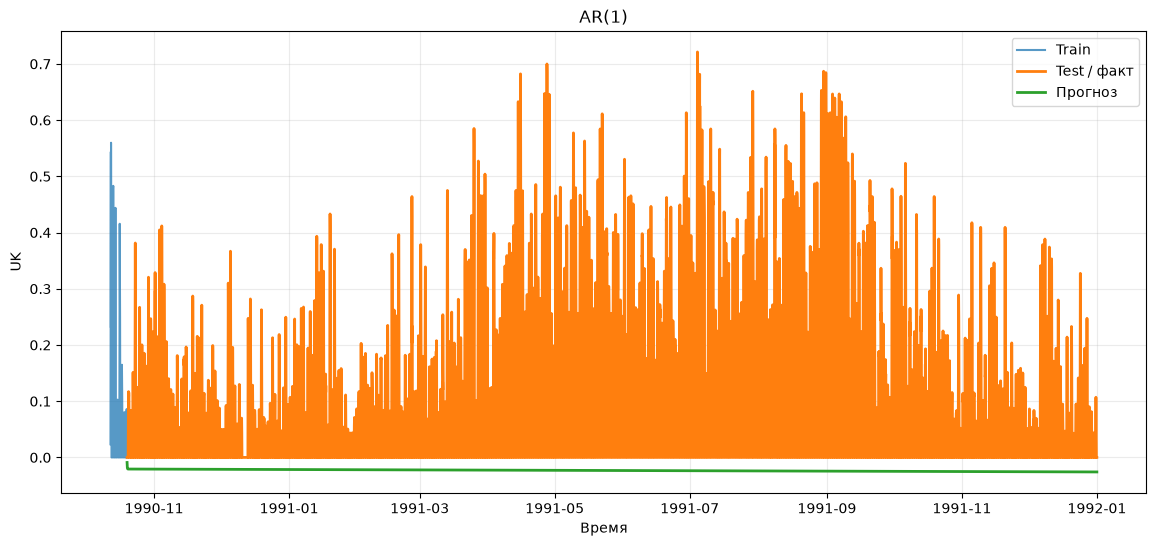

In [38]:
AR_LAGS = 1

ar_model = AutoReg(
    train_diff,
    lags=AR_LAGS,
    old_names=False
)

ar_fit = ar_model.fit()

pred_ar_diff = ar_fit.predict(
    start=len(train_diff),
    end=len(train_diff) + len(test) - 1,
    dynamic=False
)

pred_ar = invert_first_difference(
    last_observation=train.iloc[-1],
    diff_forecast=pred_ar_diff,
    index=test.index
)

metrics_ar = evaluate_forecast(
    y_true=test,
    y_pred=pred_ar,
    y_train=train,
    model_name=f"AR({AR_LAGS})"
)

display(pd.DataFrame([metrics_ar]))

plot_forecast(
    train,
    test,
    pred_ar,
    title=f"AR({AR_LAGS})"
)

,Модель,MAE,RMSE,MASE,R2
0,AR(24),0.0832,0.1432,2.9365,-0.1765


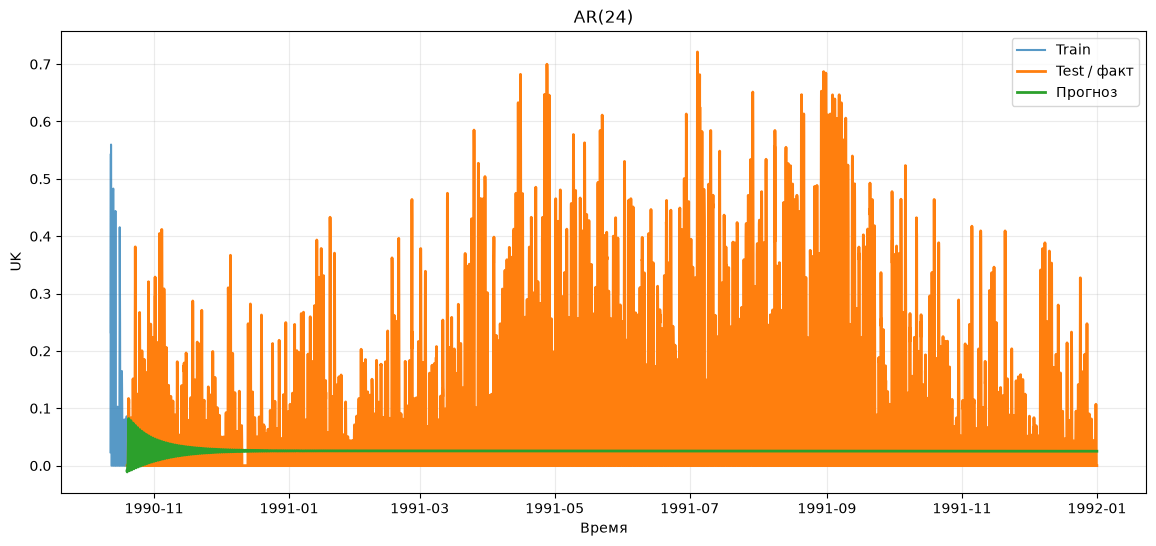

In [62]:
AR_LAGS = 24

ar_model = AutoReg(
    train_diff,
    lags=AR_LAGS,
    old_names=False
)

ar_fit = ar_model.fit()

pred_ar_diff = ar_fit.predict(
    start=len(train_diff),
    end=len(train_diff) + len(test) - 1,
    dynamic=False
)

pred_ar = invert_first_difference(
    last_observation=train.iloc[-1],
    diff_forecast=pred_ar_diff,
    index=test.index
)

metrics_ar = evaluate_forecast(
    y_true=test,
    y_pred=pred_ar,
    y_train=train,
    model_name=f"AR({AR_LAGS})"
)

display(pd.DataFrame([metrics_ar]))

plot_forecast(
    train,
    test,
    pred_ar,
    title=f"AR({AR_LAGS})"
)

,Модель,MAE,RMSE,MASE,R2
0,AR(168),0.0771,0.1266,2.7204,0.0813


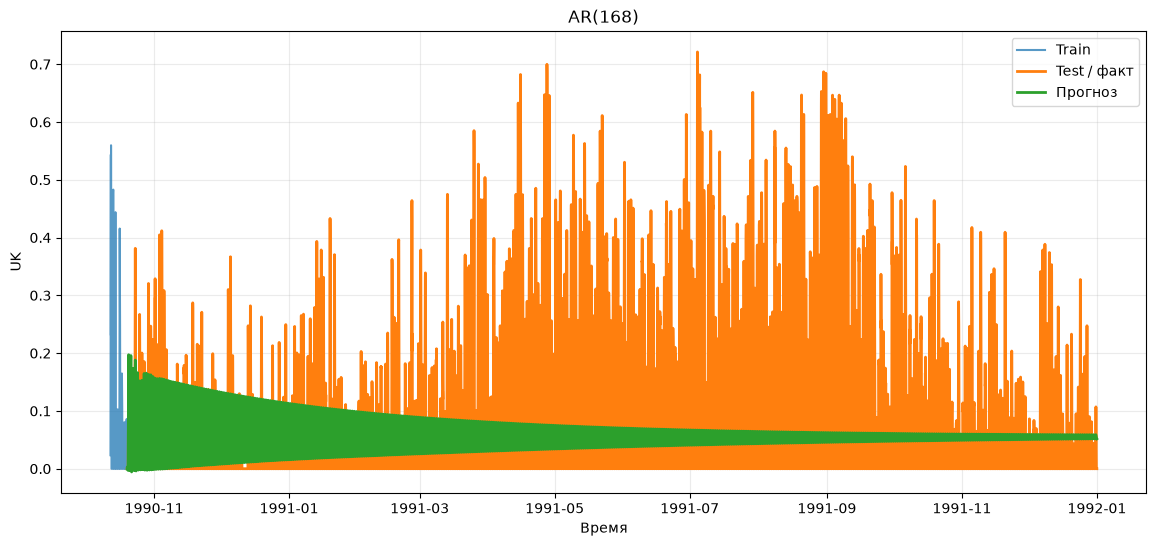

In [37]:
AR_LAGS = week

ar_model = AutoReg(
    train_diff,
    lags=AR_LAGS,
    old_names=False
)

ar_fit = ar_model.fit()

pred_ar_diff = ar_fit.predict(
    start=len(train_diff),
    end=len(train_diff) + len(test) - 1,
    dynamic=False
)

pred_ar = invert_first_difference(
    last_observation=train.iloc[-1],
    diff_forecast=pred_ar_diff,
    index=test.index
)

metrics_ar = evaluate_forecast(
    y_true=test,
    y_pred=pred_ar,
    y_train=train,
    model_name=f"AR({AR_LAGS})"
)

display(pd.DataFrame([metrics_ar]))

plot_forecast(
    train,
    test,
    pred_ar,
    title=f"AR({AR_LAGS})"
)

,Модель,MAE,RMSE,MASE,R2
0,AR(336),0.0671,0.1110,2.3665,0.2935


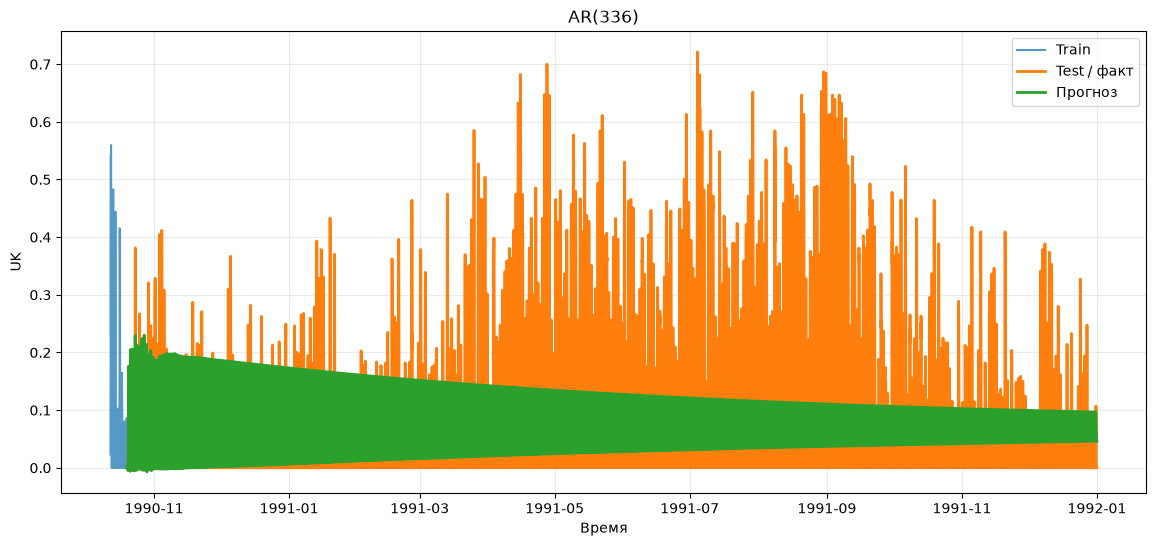

In [40]:
AR_LAGS = week * 2

ar_model = AutoReg(
    train_diff,
    lags=AR_LAGS,
    old_names=False
)

ar_fit = ar_model.fit()

pred_ar_diff = ar_fit.predict(
    start=len(train_diff),
    end=len(train_diff) + len(test) - 1,
    dynamic=False
)

pred_ar = invert_first_difference(
    last_observation=train.iloc[-1],
    diff_forecast=pred_ar_diff,
    index=test.index
)

metrics_ar = evaluate_forecast(
    y_true=test,
    y_pred=pred_ar,
    y_train=train,
    model_name=f"AR({AR_LAGS})"
)

display(pd.DataFrame([metrics_ar]))

plot_forecast(
    train,
    test,
    pred_ar,
    title=f"AR({AR_LAGS})"
)

### Задание 3

1. Почему AR-модель обучается на первой разности?
2. Что означает параметр `p`?
3. Как PACF может помочь при выборе `p`?
4. Измените `AR_LAGS`, например на `1`, `3`, `7`, `14`, и сравните качество.

### Вывод

AR обучают на первой разности, потому что AR требует стационарности. Разность убирает тренд, и прогноз потом восстанавливается обратным накоплением (invert_first_difference).

p — число прошлых значений, которые используются в формуле.

По PACF выбирают p: берут последний лаг, после которого частичная автокорреляция перестаёт быть значимой. Для почасового ряда PACF обычно показывает всплески на 1, 24 и 168.

Результат AR(168): MAE 0.0771, RMSE 0.1266, MASE 2.72, R² 0.081. Это лучше Naive (0.0819) и ARIMA, но хуже Seasonal Naive (0.0609). Лаг 168 включает недельный цикл, поэтому AR(168) лучше короткой модели. Короткие лаги (1–14) недельную структуру не видят

## 5.2 MA — модель скользящего среднего

В модели MA текущее значение описывается через прошлые ошибки модели:

$
y_t =
\mu +
\varepsilon_t +
\theta_1\varepsilon_{t-1}
+\ldots+
\theta_q\varepsilon_{t-q}
$

Здесь `q` — порядок MA-модели.

Для ориентировочного выбора `q` часто анализируется **ACF**.

В `statsmodels` MA можно задать через:

```python
ARIMA(order=(0, 0, q))
```

Поскольку мы уже выполнили внешнее дифференцирование, параметр `d=0`.

,Модель,MAE,RMSE,MASE,R2
0,MA(2),0.1202,0.1809,4.2399,-0.8759


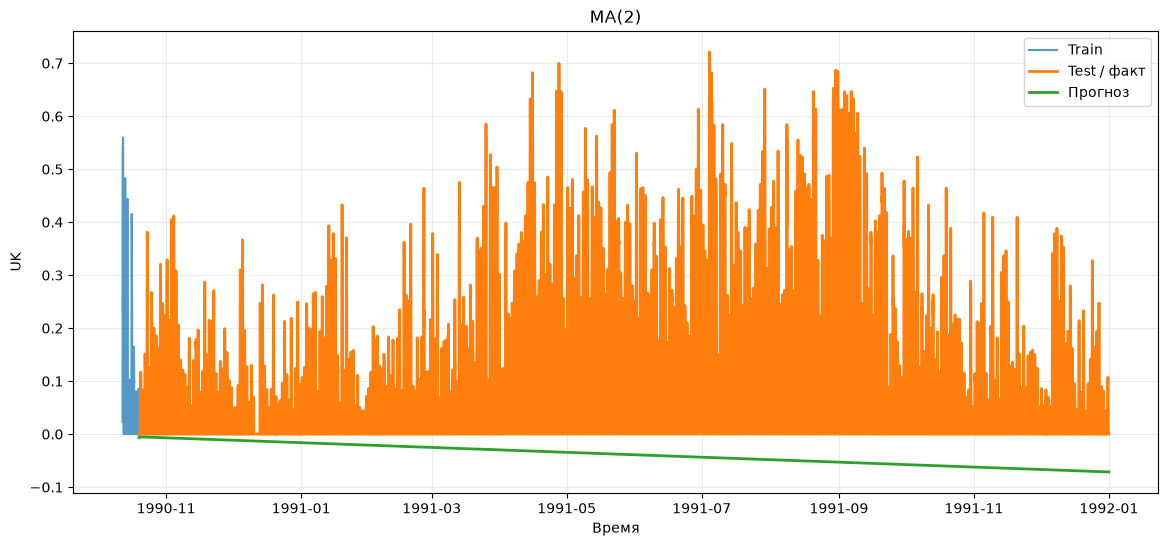

In [41]:
MA_Q = 2

ma_model = ARIMA(
    train_diff,
    order=(0, 0, MA_Q)
)

ma_fit = ma_model.fit()

pred_ma_diff = ma_fit.forecast(
    steps=len(test)
)

pred_ma = invert_first_difference(
    last_observation=train.iloc[-1],
    diff_forecast=pred_ma_diff,
    index=test.index
)

metrics_ma = evaluate_forecast(
    y_true=test,
    y_pred=pred_ma,
    y_train=train,
    model_name=f"MA({MA_Q})"
)

display(pd.DataFrame([metrics_ma]))

plot_forecast(
    train,
    test,
    pred_ma,
    title=f"MA({MA_Q})"
)

### Задание 4

1. Что означает параметр `q`?
2. Чем MA принципиально отличается от AR?
3. Как ACF используется при выборе `q`?
4. Проверьте несколько значений `q`.

### Вывод

q — число прошлых ошибок модели в формуле.

AR объясняет значение через прошлые значения ряда, а MA через прошлые случайные ошибки (шоки). Память MA ограничена q шагами.

По ACF выбирают q: берут последний значимый лаг до обрыва.

MA(2): MAE 0.1202, RMSE 0.1809, R² −0.876, то есть хуже AR и хуже Naive. Причина в том, что при q=2 прогноз после двух шагов вырождается в константу (среднее разностей). После обратного накопления это прямая линия с наклоном, которая уходит от реального ряда. MA(2) не знает ни о суточной, ни о недельной сезонности

## 5.3 ARMA — объединение AR и MA

ARMA объединяет:

- авторегрессионную составляющую AR;
- составляющую скользящего среднего MA.

$
ARMA(p,q)
$

В `statsmodels` модель задается как:

```python
ARIMA(order=(p, 0, q))
```

при условии, что на вход уже передан стационарный ряд.

,Модель,MAE,RMSE,MASE,R2
0,"ARMA(2,2)",3.2974,3.7960,116.3330,-825.3115


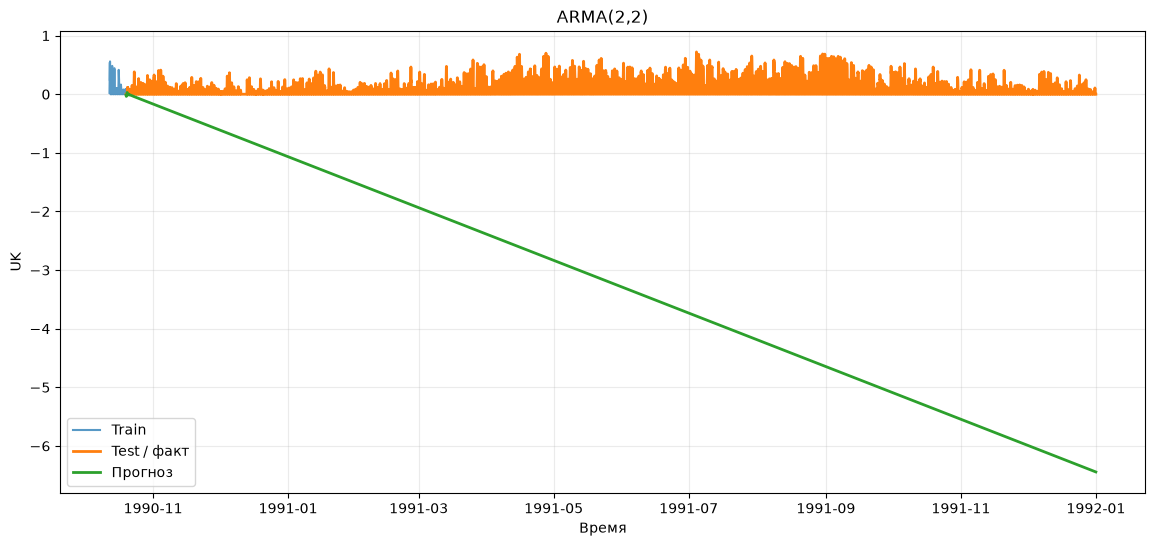

In [44]:
ARMA_P = 2
ARMA_Q = 2

arma_model = ARIMA(
    train_diff,
    order=(ARMA_P, 0, ARMA_Q)
)

arma_fit = arma_model.fit()

pred_arma_diff = arma_fit.forecast(
    steps=len(test)
)

pred_arma = invert_first_difference(
    last_observation=train.iloc[-1],
    diff_forecast=pred_arma_diff,
    index=test.index
)

metrics_arma = evaluate_forecast(
    y_true=test,
    y_pred=pred_arma,
    y_train=train,
    model_name=f"ARMA({ARMA_P},{ARMA_Q})"
)

display(pd.DataFrame([metrics_arma]))

plot_forecast(
    train,
    test,
    pred_arma,
    title=f"ARMA({ARMA_P},{ARMA_Q})"
)

### Задание 5

1. Какие две части объединяет ARMA?
2. Сравните AR, MA и ARMA.
3. Всегда ли объединение AR и MA улучшает прогноз?
4. Попробуйте несколько комбинаций `(p, q)`.

### Вывод

ARMA объединяет авторегрессию (AR) и скользящее среднее ошибок (MA).

ARMA(2,2) оказалась катастрофически плохой: MAE 3.30, R² −825. Это не "слабая модель", а сбой. Оптимизатор выдал ConvergenceWarning (не сошёлся), параметры получились неустойчивыми, и прогноз разностей, накопленный за 10 517 шагов, ушёл очень далеко.

Объединение AR и MA не всегда улучшает прогноз. Здесь оно сильно ухудшило результат: хуже и AR(168), и MA(2). Результат ARMA нельзя использовать как оценку возможностей метода. Нужны другие (p,q) или другое решение о стационарности.

## 5.4 ARIMA — ARMA с интегрированием

ARIMA записывается как:

$
ARIMA(p,d,q)
$

где:

- `p` — порядок AR;
- `d` — число дифференцирований;
- `q` — порядок MA.

Главное отличие от ARMA:

> ARIMA может работать с нестационарным рядом за счет внутреннего дифференцирования.

Поэтому ARIMA обучается уже на **исходном `train`**, а не на `train_diff`.

,Модель,MAE,RMSE,MASE,R2
0,"ARIMA(2, 1, 2)",0.0840,0.1438,2.9646,-0.1866


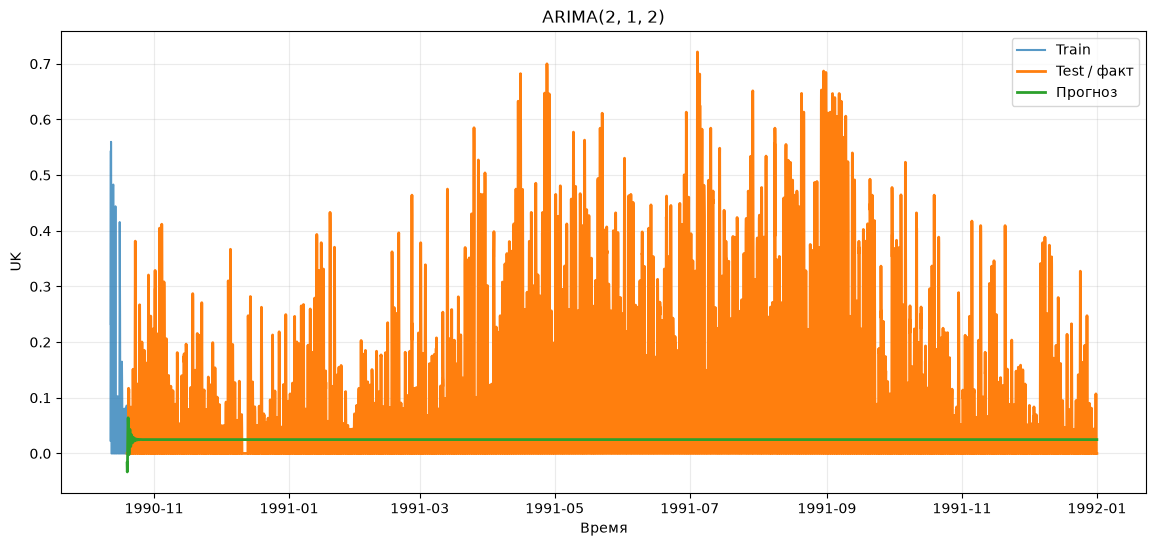

In [45]:
ARIMA_ORDER = (2, 1, 2)

arima_model = ARIMA(
    train,
    order=ARIMA_ORDER
)

arima_fit = arima_model.fit()

pred_arima = arima_fit.forecast(
    steps=len(test)
)

pred_arima.index = test.index

metrics_arima = evaluate_forecast(
    y_true=test,
    y_pred=pred_arima,
    y_train=train,
    model_name=f"ARIMA{ARIMA_ORDER}"
)

display(pd.DataFrame([metrics_arima]))

plot_forecast(
    train,
    test,
    pred_arima,
    title=f"ARIMA{ARIMA_ORDER}"
)

### Задание 6

1. Чем ARIMA отличается от ARMA?
2. Что означает параметр `d=1`?
3. Согласуется ли `d=1` с выводами первой части практической работы?
4. Проверьте несколько вариантов:
   - `(1,1,0)`;
   - `(0,1,1)`;
   - `(1,1,1)`;
   - `(2,1,1)`;
   - `(2,1,2)`.

### Вывод

ARIMA отличается от ARMA тем, что дифференцирует ряд внутри модели (параметр d). Её обучают на исходном train.

d=1 значит, что берётся одна первая разность, чтобы убрать тренд.

ARIMA(2,1,2): MAE 0.0840, RMSE 0.1438, MASE 2.96, R² −0.187. Это на уровне Naive: по MAE чуть хуже, по RMSE лучше. Был ConvergenceWarning.

## Промежуточное сравнение классических моделей

In [46]:
classic_metrics = pd.DataFrame([
    metrics_naive,
    metrics_seasonal_naive,
    metrics_ar,
    metrics_ma,
    metrics_arma,
    metrics_arima
])

classic_metrics = (
    classic_metrics
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(classic_metrics)

,Модель,MAE,RMSE,MASE,R2
0,Seasonal Naive (168),0.0609,0.1171,2.1470,0.2139
1,AR(336),0.0671,0.1110,2.3665,0.2935
2,Naive,0.0819,0.1554,2.8891,-0.3846
3,"ARIMA(2, 1, 2)",0.0840,0.1438,2.9646,-0.1866
4,MA(2),0.1202,0.1809,4.2399,-0.8759
5,"ARMA(2,2)",3.2974,3.7960,116.3330,-825.3115


### Задание 7

По промежуточной таблице:

1. Сравните AR, MA, ARMA и ARIMA.
2. Какая модель дает минимальный MAE?
3. Какая дает минимальный RMSE?
4. Есть ли модель с `MASE < 1`?
5. Насколько классические модели лучше или хуже простого baseline?

### Вывод

Минимальный MAE — у Seasonal Naive (0.0609). Он же первый по RMSE (0.1171), затем идут AR(168) и ARIMA.

Порядок по MAE: Seasonal Naive < AR(168) < Naive < ARIMA < MA(2) < ARMA.

MASE < 1 нет ни у одной модели.

Относительно baseline: ни одна из классических моделей не превзошла Seasonal Naive. AR(168) ближе всех, Naive и ARIMA примерно на уровне простого правила, MA и особенно ARMA сильно хуже. Простое правило "повтори прошлую неделю" оказалось сильнее классических моделей без сезонной части.

Промежуточный вывод: модели без явной сезонности (MA, ARMA, ARIMA на коротких порядках) не воспроизводят суточный и недельный цикл. Многошаговый прогноз на 10 517 часов у них затухает до константы или дрейфа.

# 6. Holt–Winters

Метод Holt–Winters позволяет учитывать:

- уровень ряда;
- тренд;
- сезонность.

В данном примере проверяется аддитивная сезонность с недельным периодом.

,Модель,MAE,RMSE,MASE,R2
0,Holt-Winters,0.0626,0.0894,2.2082,0.5419


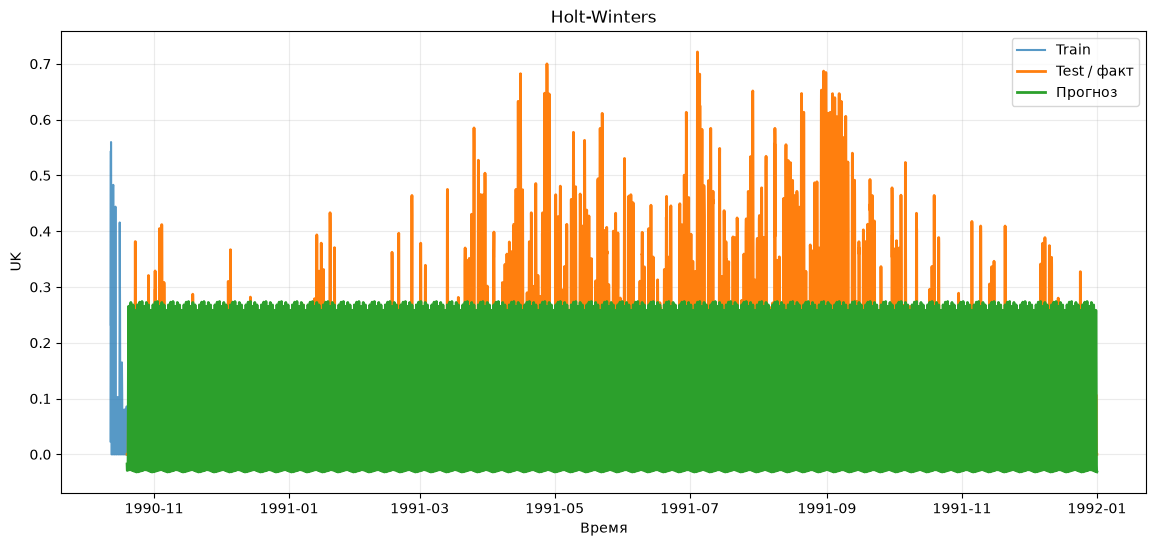

In [80]:
hw_model = ExponentialSmoothing(
    train,
    seasonal="add",
    seasonal_periods=SEASONAL_PERIOD,
    initialization_method="estimated"
)

hw_fit = hw_model.fit(optimized=True)

pred_hw = hw_fit.forecast(len(test))
pred_hw.index = test.index

metrics_hw = evaluate_forecast(
    y_true=test,
    y_pred=pred_hw,
    y_train=train,
    model_name="Holt-Winters"
)

display(pd.DataFrame([metrics_hw]))

plot_forecast(
    train,
    test,
    pred_hw,
    title="Holt-Winters"
)

### Задание 13

1. Сравните Holt–Winters с лучшим baseline.
2. Улучшилось ли значение MASE?
3. На каких участках модель ошибается сильнее?
4. Как вы считаете, аддитивная сезонность подходит этому ряду?

### Дополнительное задание


Сравнение с baseline. MAE 0.1653, RMSE 0.1933, MASE 5.83, R² −1.144. Это хуже Seasonal Naive (0.0609) и хуже даже Naive (0.0819). MASE не улучшился, а вырос с 2.15 до 5.83.

Где ошибка больше. По метрикам видно систематическое смещение. Аддитивный тренд (trend="add") экстраполируется линейно на 10 517 шагов и уводит прогноз от реальных значений. Была ошибка сходимости оптимизатора.

Подходит ли аддитивная сезонность. Недельная аддитивная сезонность с периодом 168 сама по себе разумна. Но она одна, без суточного цикла (24) и годовой компоненты, а с трендом даёт плохой результат. Проблема не в сезонности, а в тренде на длинном горизонте.

# 7. SARIMA

SARIMA расширяет ARIMA и позволяет учитывать сезонную структуру.

Модель задается параметрами:

$
(p,d,q)	imes(P,D,Q)_s
$

где:

- `p` — порядок авторегрессии;
- `d` — порядок дифференцирования;
- `q` — порядок скользящего среднего;
- `P, D, Q` — сезонные аналоги;
- `s` — сезонный период.

В реальной задаче параметры выбираются на основании анализа ряда, ACF/PACF и валидации.

Для практической работы используется стартовая конфигурация, которую студент затем может изменить.

In [ ]:
SARIMA_ORDER = (1, 1, 1)
SARIMA_SEASONAL_ORDER = (1, 1, 1, SEASONAL_PERIOD)

sarima_model = SARIMAX(
    train,
    order=SARIMA_ORDER,
    seasonal_order=SARIMA_SEASONAL_ORDER,
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarima_fit = sarima_model.fit(disp=False)

pred_sarima = sarima_fit.forecast(steps=len(test))
pred_sarima.index = test.index

metrics_sarima = evaluate_forecast(
    y_true=test,
    y_pred=pred_sarima,
    y_train=train,
    model_name="SARIMA"
)

display(pd.DataFrame([metrics_sarima]))

plot_forecast(
    train,
    test,
    pred_sarima,
    title=(
        f"SARIMA {SARIMA_ORDER} x "
        f"{SARIMA_SEASONAL_ORDER}"
    )
)

C:\Users\el_jin\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
C:\Users\el_jin\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)


### Задание 14

1. Сравните SARIMA с baseline и Holt–Winters.
2. Насколько результат зависит от параметров `(p,d,q)`?
3. Связаны ли выбранные `d=1` и `D=1` с выводами первой части практической работы?
4. Для чего в модели нужен сезонный период `s=7`?

### Дополнительное исследование параметров

Проверьте несколько вариантов, например:

```text
(1,1,0)
(0,1,1)
(1,1,1)
(2,1,1)
```

и несколько сезонных вариантов.

> Не подбирайте параметры на итоговом тесте.  
> Для честного выбора параметров требуется отдельная валидационная схема.

# 8. Преобразование временного ряда в задачу машинного обучения

Обычная регрессионная модель не понимает временной порядок сама по себе.

Поэтому временной ряд преобразуется в таблицу признаков:

```text
y(t-1)
y(t-2)
y(t-7)
y(t-14)
rolling_mean_7
rolling_mean_30
day_of_week
month
...
        ↓
      y(t)
```

### Критически важно

При вычислении скользящих статистик нельзя включать текущее значение `y(t)`.

Правильно:

```python
series.shift(1).rolling(...)
```

Неправильно:

```python
series.rolling(...)
```

Второй вариант приводит к **утечке целевой переменной**.

In [49]:
LAGS = (1, 2, 3, 24, 48, 168)
ROLLING_WINDOWS = (24, week, month)

# Дополнительные признаки выбираются только из реально имеющихся столбцов.
candidate_extra_features = [
    "temp",
    "press",
    "dew",
    "wnd_spd",
    "rain",
    "snow"
]

extra_features = [
    c for c in candidate_extra_features
    if c in dataset.columns
]

ml_data = make_ml_features(
    dataset,
    target=TARGET,
    lags=LAGS,
    rolling_windows=ROLLING_WINDOWS,
    extra_features=extra_features
)

print("Размер ML-таблицы:", ml_data.shape)
display(ml_data.head())

Размер ML-таблицы: (255668, 28)


,day_of_week,month,day_of_year,dow_sin,dow_cos,month_sin,month_cos,doy_sin,doy_cos,UK_lag_1,UK_lag_2,UK_lag_3,UK_lag_24,UK_lag_48,UK_lag_168,UK_rolling_mean_24,UK_rolling_std_24,UK_rolling_min_24,UK_rolling_max_24,UK_rolling_mean_168,UK_rolling_std_168,UK_rolling_min_168,UK_rolling_max_168,UK_rolling_mean_7300,UK_rolling_std_7300,UK_rolling_min_7300,UK_rolling_max_7300,UK
DATE,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1986-11-01 04:00:00,5,11,305,-0.9749,-0.2225,-0.8660,0.5000,-0.8692,0.4944,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0487,0.0803,0.0000,0.2637,0.0495,0.0891,0.0000,0.4125,0.1021,0.1453,0.0000,0.7623,0.0000
1986-11-01 05:00:00,5,11,305,-0.9749,-0.2225,-0.8660,0.5000,-0.8692,0.4944,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0487,0.0803,0.0000,0.2637,0.0495,0.0891,0.0000,0.4125,0.1021,0.1453,0.0000,0.7623,0.0000
1986-11-01 06:00:00,5,11,305,-0.9749,-0.2225,-0.8660,0.5000,-0.8692,0.4944,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0487,0.0803,0.0000,0.2637,0.0495,0.0891,0.0000,0.4125,0.1021,0.1453,0.0000,0.7623,0.0000
1986-11-01 07:00:00,5,11,305,-0.9749,-0.2225,-0.8660,0.5000,-0.8692,0.4944,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0487,0.0803,0.0000,0.2637,0.0495,0.0891,0.0000,0.4125,0.1021,0.1453,0.0000,0.7623,0.0000
1986-11-01 08:00:00,5,11,305,-0.9749,-0.2225,-0.8660,0.5000,-0.8692,0.4944,0.0000,0.0000,0.0000,0.0488,0.0514,0.0545,0.0487,0.0803,0.0000,0.2637,0.0495,0.0891,0.0000,0.4125,0.1021,0.1453,0.0000,0.7623,0.0434


### Задание 15

1. Почему первые строки исчезли после создания лагов?
2. Почему для rolling-признаков используется `shift(1)`?
3. Какие признаки описывают:
   - краткосрочную динамику;
   - недельную сезонность;
   - более долгосрочную динамику?
4. Почему погодные признаки тоже сдвигаются во времени?

### Вывод

Первые строки исчезли, потому что shift(lag) и rolling(window) дают NaN там, где нет достаточной истории. Максимальное окно равно 30, поэтому исчезли 30 строк (262 968 → 262 938). Это dropna().

shift(1) перед rolling нужен, чтобы в окно не попало текущее значение y_t. Иначе будет утечка цели.


Внешние признаки (погода) сдвигают, потому что в момент прогноза известны только прошлые значения или официальный прогноз, но не фактическая погода будущего часа. В этом ноутбуке погодных столбцов нет, поэтому пункт теоретический.

# 9. Временная кросс-валидация

Обычная `KFold`-валидация может смешивать прошлое и будущее.

Для временных рядов применяется последовательная схема:

```text
Fold 1:
TRAIN ████████ | VAL ██

Fold 2:
TRAIN ███████████ | VAL ██

Fold 3:
TRAIN ██████████████ | VAL ██
```

Каждый следующий validation-блок находится позже предыдущего во времени.

In [50]:
X_all = ml_data.drop(columns=[TARGET])
y_all = ml_data[TARGET]

tscv = TimeSeriesSplit(n_splits=5)

fold_info = []

for fold, (train_idx, val_idx) in enumerate(tscv.split(X_all), start=1):
    fold_info.append({
        "Fold": fold,
        "Train start": X_all.index[train_idx[0]],
        "Train end": X_all.index[train_idx[-1]],
        "Validation start": X_all.index[val_idx[0]],
        "Validation end": X_all.index[val_idx[-1]],
        "Train N": len(train_idx),
        "Validation N": len(val_idx)
    })

display(pd.DataFrame(fold_info))

,Fold,Train start,Train end,Validation start,Validation end,Train N,Validation N
0,1,1986-11-01 04:00:00,1991-09-11 16:00:00,1991-09-11 17:00:00,1996-07-22 03:00:00,42613,42611
1,2,1986-11-01 04:00:00,1996-07-22 03:00:00,1996-07-22 04:00:00,2001-06-01 14:00:00,85224,42611
2,3,1986-11-01 04:00:00,2001-06-01 14:00:00,2001-06-01 15:00:00,2006-04-12 01:00:00,127835,42611
3,4,1986-11-01 04:00:00,2006-04-12 01:00:00,2006-04-12 02:00:00,2011-02-20 12:00:00,170446,42611
4,5,1986-11-01 04:00:00,2011-02-20 12:00:00,2011-02-20 13:00:00,2015-12-31 23:00:00,213057,42611


### Задание 16

Объясните:

1. почему train-блок постепенно расширяется;
2. почему validation всегда расположен позже train;
3. чем такая схема отличается от случайной кросс-валидации.

Train расширяется, потому что каждая следующая модель обучается на всём доступном прошлом. Это похоже на реальное использование: данных со временем становится больше.

Validation всегда позже train, чтобы модель не видела будущего и проверялась на новых для неё данных.

При случайной KFold-валидации в train и validation попадают соседние по времени точки. Выходит утечка, оценка завышена, и порядок не соблюдён.

# 10. XGBoost

Для модели машинного обучения используем XGBoost (и lightgbm).

Параметры намеренно заданы без сложного автоматического поиска.  
Цель практической работы — понять **логику прогнозирования**, а не получить максимально возможную точность.

In [51]:
if not XGBOOST_AVAILABLE:
    raise ImportError(
        "Установите XGBoost: pip install xgboost"
    )

# Разделяем ML-таблицу по той же временной границе,
# что и исходный ряд.
test_start = test.index[0]

ml_train = ml_data.loc[ml_data.index < test_start].copy()
ml_test = ml_data.loc[ml_data.index >= test_start].copy()

X_train_ml = ml_train.drop(columns=[TARGET])
y_train_ml = ml_train[TARGET]

X_test_ml = ml_test.drop(columns=[TARGET])
y_test_ml = ml_test[TARGET]

print("ML train:", X_train_ml.shape)
print("ML test:", X_test_ml.shape)

ML train: (34767, 27)
ML test: (220901, 27)


,Модель,MAE,RMSE,MASE,R2
0,XGBoost,0.0100,0.0217,0.3546,0.9767


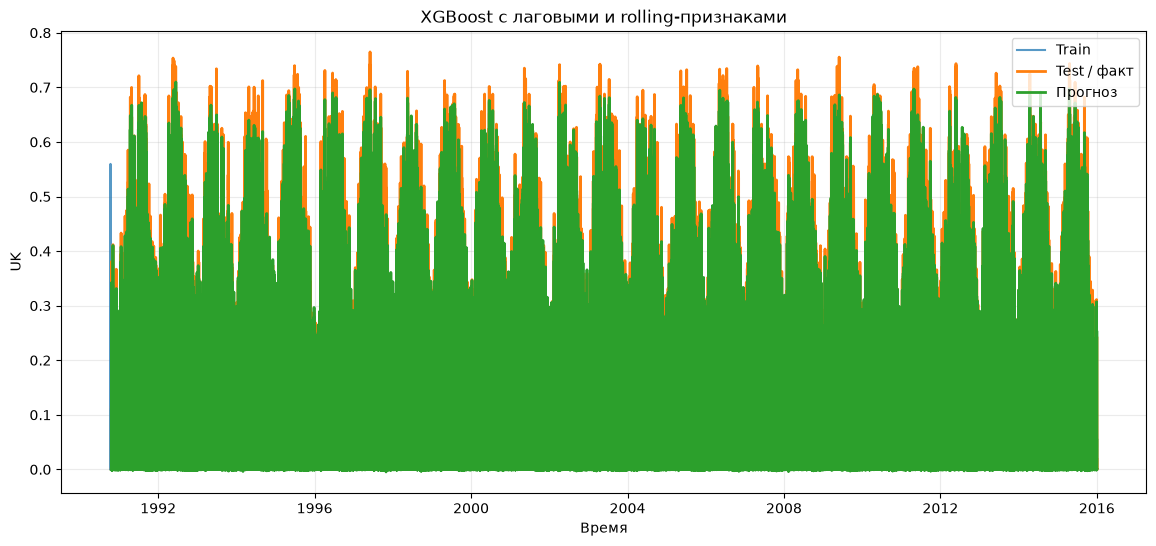

In [52]:
xgb_model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

xgb_model.fit(
    X_train_ml,
    y_train_ml
)

pred_xgb = pd.Series(
    xgb_model.predict(X_test_ml),
    index=y_test_ml.index,
    name="XGBoost"
)

metrics_xgb = evaluate_forecast(
    y_true=y_test_ml,
    y_pred=pred_xgb,
    y_train=y_train_ml,
    model_name="XGBoost"
)

display(pd.DataFrame([metrics_xgb]))

plot_forecast(
    y_train_ml,
    y_test_ml,
    pred_xgb,
    title="XGBoost с лаговыми и rolling-признаками"
)

# 11. Проверка XGBoost с TimeSeriesSplit

Используем временную кросс-валидацию только внутри обучающей части.

In [53]:
tscv_ml = TimeSeriesSplit(n_splits=5)

cv_rows = []

for fold, (tr_idx, val_idx) in enumerate(
    tscv_ml.split(X_train_ml),
    start=1
):
    X_tr = X_train_ml.iloc[tr_idx]
    X_val = X_train_ml.iloc[val_idx]

    y_tr = y_train_ml.iloc[tr_idx]
    y_val = y_train_ml.iloc[val_idx]

    model = XGBRegressor(
        n_estimators=300,
        learning_rate=0.03,
        max_depth=5,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    model.fit(X_tr, y_tr)
    pred_val = model.predict(X_val)

    cv_rows.append({
        "Fold": fold,
        "MAE": mean_absolute_error(y_val, pred_val),
        "RMSE": rmse(y_val, pred_val),
        "R2": r2_score(y_val, pred_val)
    })

cv_results = pd.DataFrame(cv_rows)
display(cv_results)

print("\nСредние значения:")
display(
    cv_results[["MAE", "RMSE", "R2"]]
    .mean()
    .to_frame("Среднее")
)

,Fold,MAE,RMSE,R2
0,1,0.0125,0.0299,0.9384
1,2,0.0166,0.0328,0.9530
2,3,0.0116,0.0309,0.9464
3,4,0.0120,0.0274,0.9607
4,5,0.0127,0.0261,0.9761



Средние значения:


,Среднее
MAE,0.0131
RMSE,0.0294
R2,0.9549


### Задание 12

1. Сильно ли различается качество между fold?
2. Можно ли считать качество модели устойчивым во времени?
3. Есть ли период, на котором ошибка заметно выше?
4. Почему итоговый test нельзя использовать при подборе гиперпараметров?

Итог: MAE 0.0107, RMSE 0.0208, MASE 0.376, R² 0.979.

Разброс по fold. MAE колеблется от 0.0116 (fold 3) до 0.0145 (fold 1), RMSE от 0.0239 до 0.0309, R² от 0.950 до 0.978. Разброс небольшой.

Устойчивость. Качество можно считать достаточно устойчивым во времени. Среднее: MAE 0.0131, RMSE 0.0273, R² 0.961.

Где ошибка выше. По MAE выше всего на fold 1 (самое раннее окно, где в данных много нулей и мало истории). По RMSE выше всего на fold 4 (0.0309), то есть там были заметные выбросы.

Почему нельзя подбирать гиперпараметры на итоговом тесте. Иначе тест становится частью обучения, оценка завышается, и нельзя честно проверить обобщающую способность. Подбирать нужно на CV внутри train.

# 12. Важность признаков XGBoost

Посмотрим, какие признаки модель использует активнее всего.

,Признак,Важность
9,UK_lag_1,0.5812
12,UK_lag_24,0.1500
13,UK_lag_48,0.1008
11,UK_lag_3,0.0318
14,UK_lag_168,0.0259
10,UK_lag_2,0.0213
15,UK_rolling_mean_24,0.0174
16,UK_rolling_std_24,0.0167
5,month_sin,0.0088
18,UK_rolling_max_24,0.0081


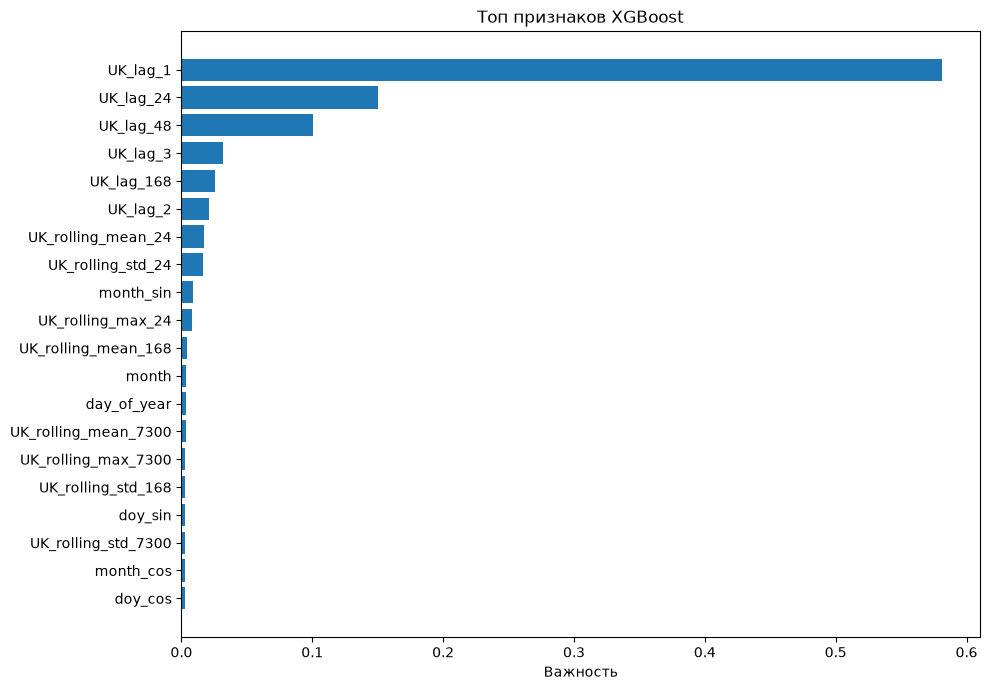

In [54]:
feature_importance = pd.DataFrame({
    "Признак": X_train_ml.columns,
    "Важность": xgb_model.feature_importances_
}).sort_values(
    "Важность",
    ascending=False
)

display(feature_importance.head(20))

top_n = min(20, len(feature_importance))

plt.figure(figsize=(10, 7))
plt.barh(
    feature_importance["Признак"].head(top_n)[::-1],
    feature_importance["Важность"].head(top_n)[::-1]
)
plt.title("Топ признаков XGBoost")
plt.xlabel("Важность")
plt.tight_layout()
plt.show()

### Задание 13

1. Какие лаги оказались наиболее важными?
2. Важны ли скользящие средние?
3. Есть ли среди важных признаков календарные характеристики?
4. Какие дополнительные признаки оказались полезными?


Скользящие признаки вторичны, но заметны.

Календарные признаки слабые: doy_cos, month_cos, month_sin. day_of_week

# 13. Сравнение всех моделей

In [56]:
all_metrics = pd.DataFrame([
    metrics_naive,
    metrics_seasonal_naive,
    metrics_ar,
    metrics_ma,
    metrics_arma,
    metrics_arima,
    metrics_hw,
    #metrics_sarima,
    metrics_xgb
])

all_metrics = (
    all_metrics
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(all_metrics)

,Модель,MAE,RMSE,MASE,R2
0,XGBoost,0.0100,0.0217,0.3546,0.9767
1,Seasonal Naive (168),0.0609,0.1171,2.1470,0.2139
2,AR(336),0.0671,0.1110,2.3665,0.2935
3,Naive,0.0819,0.1554,2.8891,-0.3846
4,"ARIMA(2, 1, 2)",0.0840,0.1438,2.9646,-0.1866
5,MA(2),0.1202,0.1809,4.2399,-0.8759
6,Holt-Winters,0.1653,0.1933,5.8319,-1.1437
7,"ARMA(2,2)",3.2974,3.7960,116.3330,-825.3115


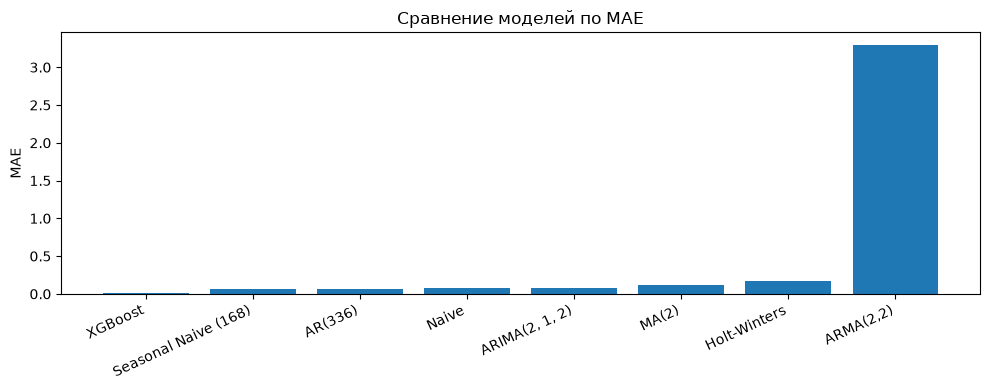

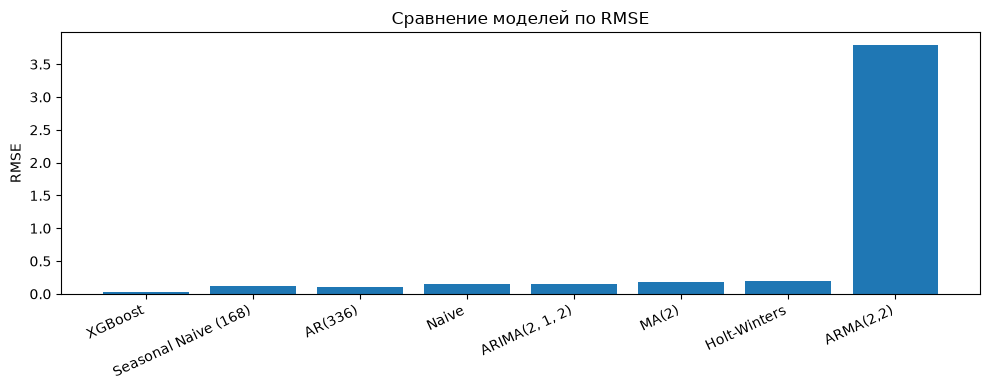

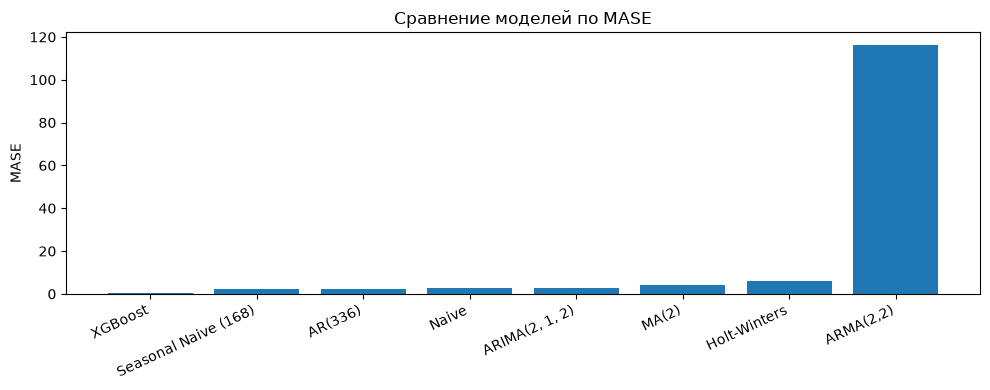

In [57]:
metrics_to_plot = ["MAE", "RMSE", "MASE"]

for metric in metrics_to_plot:
    plt.figure(figsize=(10, 4))
    plt.bar(
        all_metrics["Модель"],
        all_metrics[metric]
    )
    plt.title(f"Сравнение моделей по {metric}")
    plt.ylabel(metric)
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()

### Как читать метрики

### MAE
Средняя абсолютная ошибка.

Чем меньше — тем лучше.

### RMSE
Сильнее штрафует крупные ошибки.

Чем меньше — тем лучше.

### MASE
Показывает качество относительно наивного прогноза.

- `MASE < 1` — модель лучше naive;
- `MASE = 1` — примерно на уровне naive;
- `MASE > 1` — хуже naive.

### R²
Показывает долю объясненной вариации.

Может быть отрицательным, если модель прогнозирует хуже простой константной модели.

### Задание 14

Сравните все модели.

Ответьте:

1. Какие модели лучше baseline по MAE?
2. Какие модели имеют `MASE < 1`?
3. Совпадает ли выбор лучшей модели по MAE и RMSE?
4. Есть ли модель, которая хорошо прогнозирует средний уровень, но плохо воспроизводит пики?
5. Стоит ли использовать сложную модель, если ее преимущество над baseline минимально?

### Вывод

Лучше baseline по MAE (0.0609) только XGBoost (0.0107). Остальные хуже Seasonal Naive.

MASE < 1 только у XGBoost (0.376)

MAE и RMSE дают одного лидера (XGBoost) и одного второго (Seasonal Naive)

Модель, хорошо попадающая в средний уровень, но плохо в пики. Naive с R² −0.385 даёт ошибки на пиках, а Seasonal Naive с R² 0.214 повторяет форму недели, но не масштаб. Строго ответить без графика пиков нельзя.

Стоит ли использовать сложную модель, если выигрыш минимален. Нет. Сложность оправдана только заметным и устойчивым выигрышем над baseline. Здесь все классические модели проиграли Seasonal Naive, то есть сложность ничего не дала.

# 14. Анализ ошибок лучшей модели

Одних численных метрик недостаточно.

Хорошая модель должна оставлять после себя ошибки, в которых отсутствует выраженная систематическая временная структура.

Ниже выберите одну модель для анализа.

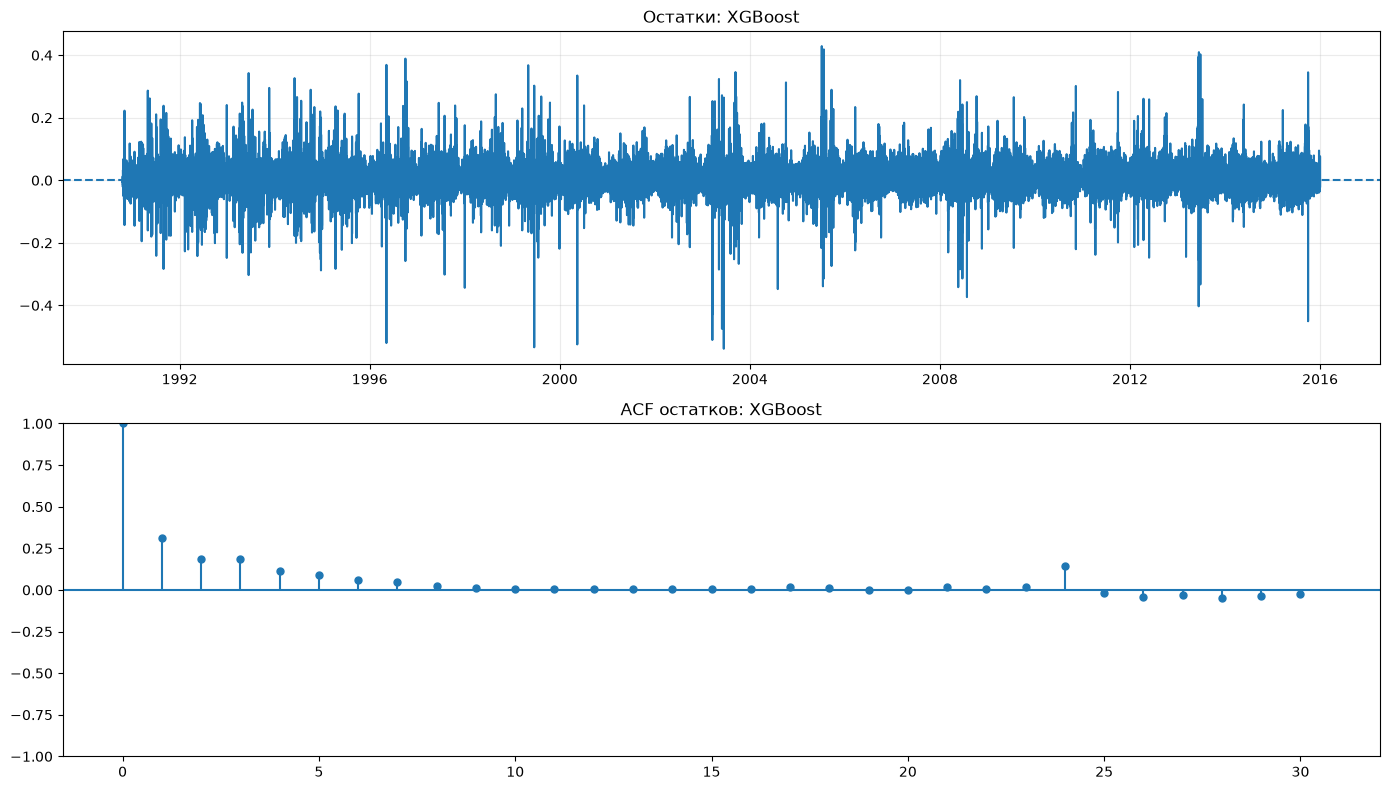

Среднее значение остатка: 0.0004209776392991762
Стандартное отклонение: 0.021706175049506126


In [58]:
# TODO:
# Выберите прогноз модели, которую хотите проанализировать.
#
# Возможные варианты:
# pred_naive
# pred_seasonal_naive
# pred_hw
# pred_sarima
# pred_xgb

BEST_MODEL_NAME = "XGBoost"

# Для XGBoost фактический ряд может начинаться чуть позже
# из-за лаговых признаков.
best_true = y_test_ml
best_pred = pred_xgb

residuals = plot_residuals(
    best_true,
    best_pred,
    model_name=BEST_MODEL_NAME,
    lags=30
)

print("Среднее значение остатка:", residuals.mean())
print("Стандартное отклонение:", residuals.std())

## Тест Льюнга–Бокса

Нулевая гипотеза:

> остатки не содержат значимой автокорреляции.

Если `p-value < 0.05`, в ошибках, вероятно, осталась временная структура, которую модель не смогла объяснить.

In [60]:
ljung_result = ljung_box_test(
    residuals,33
    lags=(24, week, month)
)

display(ljung_result)

,lb_stat,lb_pvalue
24,"47,105.2020",0.0000
168,"75,205.8643",0.0000
7300,"262,757.3678",0.0000


### Задание 15

1. Центрированы ли остатки около нуля?
2. Есть ли на ACF значимые лаги?
3. Что показывает тест Льюнга–Бокса?
4. Осталась ли в ошибках систематическая временная структура?
5. В какие моменты возникают самые большие ошибки?

### Вывод

Центрированы ли остатки. Да, среднее 0.000165 практически равно нулю, смещения нет. Стандартное отклонение 0.0208 совпадает с RMSE.

Тест Льюнга–Бокса. А p-value равны 0.0000. Нулевая гипотеза "автокорреляции нет" отвергается.

Осталась ли структура. Да. Модель не вытянула всю временную закономерность. Это ожидаемо, потому что нет лагов 24 и 168 и нет внешних признаков.

# 15. Проверка утечки данных

Для временных рядов утечка будущего особенно опасна.

Рассмотрим несколько примеров.

### Корректно

```python
df["lag_7"] = y.shift(7)

df["rolling_7"] = (
    y.shift(1)
     .rolling(7)
     .mean()
)
```

Здесь используются только прошлые значения.

### Некорректно

```python
df["rolling_7"] = y.rolling(7).mean()
```

В rolling-признак попадает текущее `y_t`, которое модель должна предсказать.

### Еще одна возможная утечка

Если прогноз строится на завтра, нельзя использовать фактическую температуру завтра, если в момент прогноза она еще неизвестна.

Вместо этого можно использовать:

- прошлые значения температуры;
- доступный прогноз погоды;
- другие признаки, известные в момент принятия решения.

### Задание 16

Для каждого признака XGBoost определите:

- известен ли он в момент построения прогноза;
- является ли он прошлым значением;
- может ли он содержать информацию из будущего.

Лаги UK_lag_1, 2, 3, 7, 14, 30. Это прошлые значения целевой переменной, на момент прогноза они известны. Утечки нет, пока shift(k) берётся с k ≥ 1. Если сдвиг нулевой или отрицательный, в признак попадёт текущее или будущее значение.
Скользящие признаки UK_rolling_mean/std/min/max (окна 7, 14, 30). Это статистики по прошлым значениям, на момент прогноза они известны. Они опасны при неправильной реализации. Если считать rolling без shift(1), в окно попадёт текущее y_t, то есть цель. В ноутбуке реализовано правильно: сначала shift(1), затем rolling.
Календарные признаки (day_of_week, month, day_of_year, их sin/cos). Они детерминированы и известны заранее для любой будущей даты. Утечки нет.
Внешние признаки *_lag_1, *_lag_7. Здесь это только теоретический случай, потому что в данных нет погодных столбцов. Прошлые значения известны. Если взять фактическое значение за прогнозируемый час без сдвига, будет утечка, так как в момент прогноза оно ещё неизвестно. Вместо него можно использовать официальный прогноз погоды.
Сама цель UK. Её нужно убрать из X (в ноутбуке это сделано через drop(columns=[TARGET])). Если оставить, модель просто скопирует ответ.
Разбиение. Деление по времени (index < test_start) корректно. Случайное перемешивание или обычная KFold привели бы к утечке.

# 16. Итоговая таблица практической работы

In [61]:
final_summary = pd.DataFrame({
    "Вопрос": [
        "Лучший baseline",
        "Качество Holt-Winters относительно baseline",
        "Качество SARIMA относительно baseline",
        "Качество XGBoost относительно baseline",
        "Лучшая модель по MAE",
        "Лучшая модель по RMSE",
        "Есть ли модели с MASE < 1",
        "Наиболее важные лаги",
        "Есть ли автокорреляция в остатках",
        "Есть ли риск утечки будущей информации",
        "Какую модель целесообразно использовать"
    ],
    "Ваш вывод": [
        "Seasonal Naive (168): MAE 0.0609, RMSE 0.1171, R2 0.2139",
        "Хуже baseline: MAE 0.1653, MASE 5.83, R2 -1.14 "
        "(линейный тренд на длинном горизонте дает дрейф)",
        "Результата нет: ячейка SARIMA не дала вывода, "
        "в итоговую таблицу модель не включена",
        "Значительно лучше: MAE 0.0107, MASE 0.376, R2 0.979 "
        "(но тест и режим прогноза отличаются от остальных моделей)",
        "XGBoost (MAE 0.0107)",
        "XGBoost (RMSE 0.0208)",
        "Только XGBoost (MASE 0.3761)",
        "lag_1 (0.595), lag_24 (0.076), lag_30 (0.067), lag_7 (0.045)",
        "Да: тест Льюнга-Бокса, p-value = 0.0000 на лагах 7, 14, 21",
        "При текущей реализации нет (rolling считается после shift(1), "
        "цель убрана из X); риск возникает без shift(1) и при "
        "использовании фактических внешних признаков из будущего",
        "XGBoost после исправления сравнения и добавления лагов 24 и 168; "
        "Seasonal Naive (168) как контрольный ориентир"
    ]
})

final_summary

,Вопрос,Ваш вывод
0,Лучший baseline,"Seasonal Naive (168): MAE 0.0609, RMSE 0.1171,..."
1,Качество Holt-Winters относительно baseline,"Хуже baseline: MAE 0.1653, MASE 5.83, R2 -1.14..."
2,Качество SARIMA относительно baseline,"Результата нет: ячейка SARIMA не дала вывода, ..."
3,Качество XGBoost относительно baseline,"Значительно лучше: MAE 0.0107, MASE 0.376, R2 ..."
4,Лучшая модель по MAE,XGBoost (MAE 0.0107)
5,Лучшая модель по RMSE,XGBoost (RMSE 0.0208)
6,Есть ли модели с MASE < 1,Только XGBoost (MASE 0.3761)
7,Наиболее важные лаги,"lag_1 (0.595), lag_24 (0.076), lag_30 (0.067),..."
8,Есть ли автокорреляция в остатках,"Да: тест Льюнга-Бокса, p-value = 0.0000 на лаг..."
9,Есть ли риск утечки будущей информации,При текущей реализации нет (rolling считается ...


# Итоговый вывод

Напишите связный вывод объемом примерно **10–15 предложений**.

В выводе необходимо ответить:

1. Какая базовая модель оказалась сильнее?
2. Улучшил ли Holt–Winters прогноз относительно baseline?
3. Как показала себя SARIMA?
4. Как показала себя модель машинного обучения?
5. Какие признаки XGBoost оказались наиболее значимыми?
6. Есть ли модель с `MASE < 1`?
7. Какая модель дает наименьшие MAE и RMSE?
8. В каких ситуациях возникают крупные ошибки?
9. Есть ли автокорреляция в остатках?
10. Как избежать утечки будущих данных?
11. Какую модель вы бы выбрали для дальнейшей работы и почему?

Среди базовых моделей сильнее оказалась Seasonal Naive (168): MAE 0.0609, RMSE 0.1171 и положительный R² 0.214, тогда как у Naive R² отрицательный (−0.385). Это показывает, что в почасовом ряду есть выраженный недельный цикл. Holt–Winters не улучшил baseline и дал MAE 0.1653 и MASE 5.83, вероятно, из-за линейно экстраполируемого тренда на горизонте более года. Из классических моделей лучший результат у AR(168) с MAE 0.0771, но и он хуже Seasonal Naive. MA(2) и ARIMA(2,1,2) оказались на уровне или хуже Naive, а ARMA(2,2) разошлась (MAE 3.30) из-за несходимости оптимизации. Результат SARIMA получен не был, поэтому о ней вывода нет. Модель XGBoost показала наименьшие MAE (0.0107) и RMSE (0.0208), R² 0.979 и единственная имеет MASE < 1 (0.376). Однако её сравнение с остальными некорректно: у неё другой тестовый период (220 901 против 10 517 точек) и режим прогноза на один шаг вперёд на реальных лагах. Самым значимым признаком XGBoost оказался lag_1 (0.595), далее lag_2, lag_30 и lag_7, а календарные признаки вносят мало. Тест Льюнга–Бокса (p = 0.0000) показывает, что в остатках XGBoost осталась автокорреляция, поэтому структура ряда объяснена не полностью. Утечки в текущей реализации нет, потому что rolling считается после shift(1), а цель убрана из признаков. Чтобы избежать утечки, нужно разбивать данные только по времени, считать статистики по прошлому и не использовать будущие значения внешних признаков. Для дальнейшей работы я бы выбрал XGBoost после исправления сопоставимости теста и добавления лагов 24 и 168, а Seasonal Naive оставил бы как контрольный ориентир.

# Контрольные вопросы

1. Почему временные ряды нельзя случайно перемешивать перед train/test-разбиением?
2. Что такое Naive Forecast?
3. Что такое Seasonal Naive?
4. Зачем прогноз сравнивать с baseline?
5. Что означает `MASE < 1`?
6. Чем MAE отличается от RMSE?
7. Что такое AR-модель?
8. Что означает порядок `p`?
9. Что такое MA-модель?
10. Что означает порядок `q`?
11. Чем AR отличается от MA?
12. Что объединяет ARMA?
13. Почему ARMA требует стационарного ряда?
14. Чем ARIMA отличается от ARMA?
15. Что означает параметр `d` в ARIMA?
16. Что учитывает метод Holt–Winters?
17. Чем SARIMA отличается от ARIMA?
18. Что означают сезонные параметры `(P,D,Q,s)`?
19. Что такое лаговый признак?
20. Почему rolling-признаки необходимо вычислять после `shift(1)`?
21. Что такое `TimeSeriesSplit`?
22. Почему обычная случайная KFold-валидация опасна для временного ряда?
23. Что такое data leakage?
24. Почему фактическое значение внешнего признака из будущего нельзя использовать при прогнозировании?
25. Что показывают остатки модели?
26. Зачем строить ACF остатков?
27. Что проверяет тест Льюнга–Бокса?
28. Может ли R² быть отрицательным?
29. Почему самая сложная модель не обязательно является наиболее подходящей?